In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import zipfile
import os

zip_path = '/content/drive/MyDrive/pneumonia_Dataset.zip'

extract_path = '/content/dataset'

print("Extracting data... Please wait!")
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)
print("Extraction Completed Successfully!")

print("Available classes (folders):", os.listdir(extract_path))

Mounted at /content/drive
Extracting data... Please wait!
Extraction Completed Successfully!
Available classes (folders): ['chest_xray']


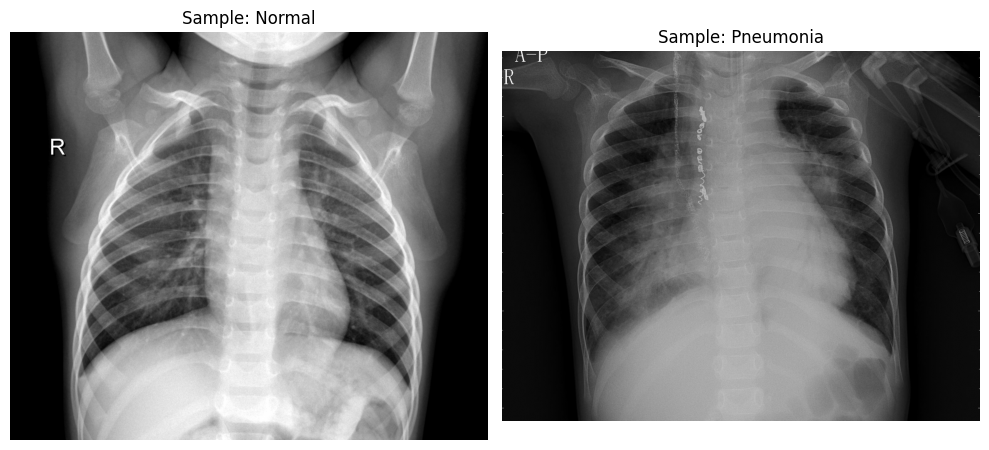

In [ ]:
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# Dataset path
base_dir = '/content/dataset/chest_xray'

# Train folder paths
train_dir = os.path.join(base_dir, 'train')

normal_path = os.path.join(train_dir, 'NORMAL')
pneumonia_path = os.path.join(train_dir, 'PNEUMONIA')

# Get image files
normal_images = os.listdir(normal_path)
pneumonia_images = os.listdir(pneumonia_path)

# Select sample images
sample_normal_img = os.path.join(normal_path, normal_images[0])
sample_pneumonia_img = os.path.join(pneumonia_path, pneumonia_images[0])

# Read images
img_normal = mpimg.imread(sample_normal_img)
img_pneumonia = mpimg.imread(sample_pneumonia_img)

# Display images
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(img_normal, cmap='gray')
axes[0].set_title('Sample: Normal')
axes[0].axis('off')

axes[1].imshow(img_pneumonia, cmap='gray')
axes[1].set_title('Sample: Pneumonia')
axes[1].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
import os
import cv2
import numpy as np
from sklearn.model_selection import train_test_split

# Dataset path
base_dir = '/content/dataset/chest_xray/train'

# Class paths
normal_path = os.path.join(base_dir, 'NORMAL')
pneumonia_path = os.path.join(base_dir, 'PNEUMONIA')

# Get image files
normal_images = os.listdir(normal_path)
pneumonia_images = os.listdir(pneumonia_path)

X = []
y = []

IMG_SIZE = 128

print("Data Preparation will starts now")

# Load Normal images (Label = 0)
for img_name in normal_images:
    img_path = os.path.join(normal_path, img_name)

    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

    if img is not None:
        img_resized = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        X.append(img_resized)
        y.append(0)

# Load Pneumonia images (Label = 1)
for img_name in pneumonia_images:
    img_path = os.path.join(pneumonia_path, img_name)

    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

    if img is not None:
        img_resized = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        X.append(img_resized)
        y.append(1)

# Convert to NumPy arrays
X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.int32)

# Normalize images
X = X / 255.0

# Reshape for CNN
X = X.reshape(-1, IMG_SIZE, IMG_SIZE, 1)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Data Preparation Completed!")
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)


Data Preparation will starts now
Data Preparation Completed!
X_train shape: (4172, 128, 128, 1)
X_test shape: (1044, 128, 128, 1)
y_train shape: (4172,)
y_test shape: (1044,)


In [ ]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, Flatten,
    Dense, Dropout, Input
)

print("Building CNN Model Architecture!")

# Create CNN Model
model = Sequential()

# Input Layer
model.add(Input(shape=(128, 128, 1)))

# First Convolutional Layer
model.add(Conv2D(32, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))

# Second Convolutional Layer
model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))

# Third Convolutional Layer
model.add(Conv2D(128, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))

# Flatten Layer
model.add(Flatten())

# Fully Connected Layer
model.add(Dense(128, activation='relu'))

# Dropout Layer
model.add(Dropout(0.5))

# Output Layer
model.add(Dense(1, activation='sigmoid'))

print("Model Building Successful!")
print("-" * 50)

# Model Summary
model.summary()


Building CNN Model Architecture!
Model Building Successful!
--------------------------------------------------


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,193 (12.60 MB)

 Trainable params: 3,304,193 (12.60 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping

print("Model Compiling!")

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

print("Training Starts... GPU Processing!")

history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=16,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

print("-" * 50)
print("Model Training Successfully Completed!")



Model Compiling!
Training Starts... GPU Processing!
Epoch 1/20
209/209 ━━━━━━━━━━━━━━━━━━━━ 16s 43ms/step - accuracy: 0.8762 - loss: 0.2989 - val_accuracy: 0.9605 - val_loss: 0.1134
Epoch 2/20
209/209 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9419 - loss: 0.1573 - val_accuracy: 0.9665 - val_loss: 0.0914
Epoch 3/20
209/209 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9547 - loss: 0.1208 - val_accuracy: 0.9725 - val_loss: 0.0743
Epoch 4/20
209/209 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.9655 - loss: 0.0896 - val_accuracy: 0.9725 - val_loss: 0.0824
Epoch 5/20
209/209 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9694 - loss: 0.0823 - val_accuracy: 0.9796 - val_loss: 0.0627
Epoch 6/20
209/209 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9727 - loss: 0.0702 - val_accuracy: 0.9808 - val_loss: 0.0560
Epoch 7/20
209/209 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9784 - loss: 0.0620 - val_accuracy: 0.9784 - val_loss: 0.0684
Epoch 8/20
209/209 ━━━━━━━━━━━━━━━━━━━━ 2s 1

Evaluating Model Performance... Please wait!
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step

--- Classification Report ---
               precision    recall  f1-score   support

   Normal (0)       0.93      0.99      0.96       268
Pneumonia (1)       1.00      0.98      0.99       776

     accuracy                           0.98      1044
    macro avg       0.96      0.98      0.97      1044
 weighted avg       0.98      0.98      0.98      1044

Test Accuracy: 97.89 %


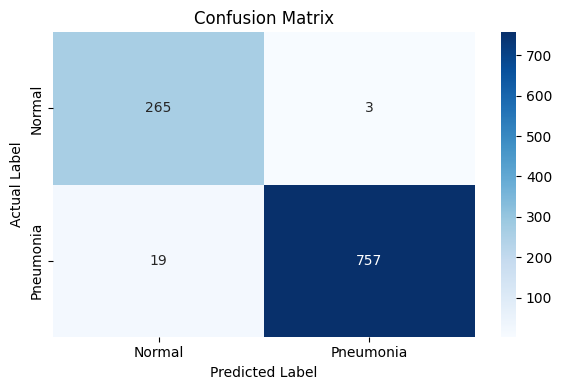

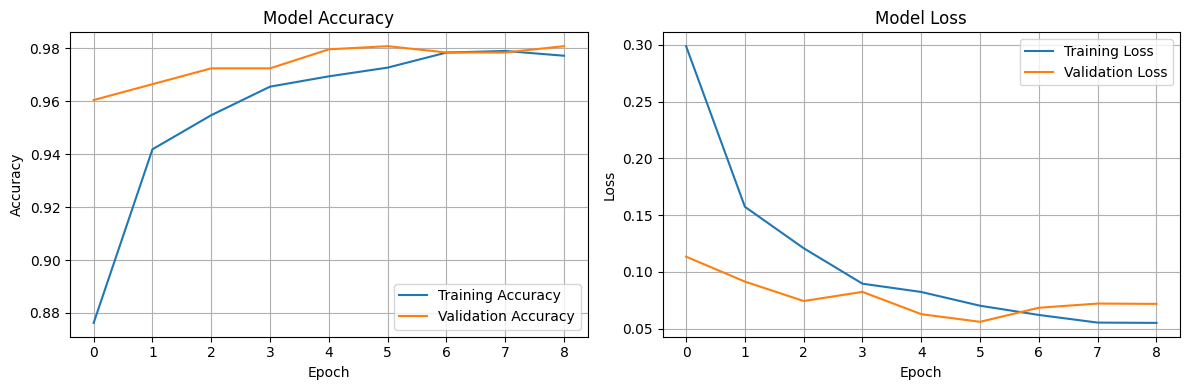

Model Evaluation Completed!


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

print("Evaluating Model Performance... Please wait!")

# Predict test data
y_pred_prob = model.predict(X_test)

# Convert probabilities into classes
y_pred_classes = (y_pred_prob > 0.5).astype(int).ravel()

# Classification Report
print("\n--- Classification Report ---")

print(classification_report(
    y_test,
    y_pred_classes,
    labels=[0, 1],
    target_names=['Normal (0)', 'Pneumonia (1)'],
    zero_division=0
))

# Calculate Accuracy
accuracy = accuracy_score(y_test, y_pred_classes)
print("Test Accuracy:", round(accuracy * 100, 2), "%")

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_classes, labels=[0, 1])

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal', 'Pneumonia'],
    yticklabels=['Normal', 'Pneumonia']
)

plt.title('Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.show()

# Accuracy and Loss Graphs
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Accuracy Graph
axes[0].plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

axes[0].plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

axes[0].set_title('Model Accuracy')
axes[0].set_ylabel('Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].legend()
axes[0].grid(True)

# Loss Graph
axes[1].plot(
    history.history['loss'],
    label='Training Loss'
)

axes[1].plot(
    history.history['val_loss'],
    label='Validation Loss'
)

axes[1].set_title('Model Loss')
axes[1].set_ylabel('Loss')
axes[1].set_xlabel('Epoch')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

print("Model Evaluation Completed!")

In [ ]:
# Save the trained model
model.save("/content/neurovision_pneumonia_model.h5")


In [ ]:
from google.colab import files

# Download the saved model file to your local machine
files.download('/content/neurovision_pneumonia_model.h5')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>